# Fast Food Marketing A/B Testing Overview

## About the Dataset

A fast-food chain is preparing to launch a new menu item but is unsure which of three potential promotional campaigns will be the most effective. To answer this, the company tested the campaigns in several randomly chosen markets. Each location was assigned a different promotion, and weekly sales data was collected over a four-week period to assess the impact of each strategy.

## Goal
The goal of this project is to analyze the A/B testing results and determine which of the three marketing strategies performs best. We aim to identify whether the observed differences in sales across the promotion groups are statistically significant and recommend the most effective campaign based on the data.

## Target Metric
- **SalesInThousands**: Weekly sales in thousands of USD.
- We'll calculate the **average weekly sales** per campaign group.
- This metric directly reflects the success of a promotion in driving revenue.

## Dashboard
- One chart must show how sales change over time (by week).
- Another chart should compare total or average sales by promotion group.
- Use matplotlib, seaborn and Streamlit.

# Data Analysis

## Import Libraries and Basic Data Exploration

- In block below we will import all the necessary libraries and load the dataset.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare
import numpy as np
from scipy.stats import sem, t
import seaborn as sns
from scipy.stats import shapiro, levene
import scikit_posthocs as sp
from scipy.stats import kruskal

plt.style.use('seaborn-v0_8-white')

In [20]:
df = pd.read_csv("datasets/WA_Marketing-Campaign.csv")
df.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


- Check for null values and data types.
- Check for duplicates.
- Check unique values in the `Promotion`

In [21]:
print(df.info())

duplicates = df.duplicated()
duplicate_rows = df[duplicates]

print("Duplicate rows:")
print(duplicate_rows)

print("\nPromotion groups:", df['Promotion'].unique(), end="\n")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MarketID          548 non-null    int64  
 1   MarketSize        548 non-null    object 
 2   LocationID        548 non-null    int64  
 3   AgeOfStore        548 non-null    int64  
 4   Promotion         548 non-null    int64  
 5   week              548 non-null    int64  
 6   SalesInThousands  548 non-null    float64
dtypes: float64(1), int64(5), object(1)
memory usage: 30.1+ KB
None
Duplicate rows:
Empty DataFrame
Columns: [MarketID, MarketSize, LocationID, AgeOfStore, Promotion, week, SalesInThousands]
Index: []

Promotion groups: [3 2 1]


## Sales Distribution Across Promotions (Percentage)

In this section, we will calculate the percentage distribution of sales across different promotions.

- Group data by `Promotion` and sum the `SalesInThousands`.

In [22]:
sales_dist = df.groupby('Promotion')['SalesInThousands'].sum().reset_index()
sales_dist['Percentage'] = round((sales_dist['SalesInThousands'] / sales_dist['SalesInThousands'].sum()) * 100, 2)

print("Sales Distribution by Promotion", end="\n")
print(sales_dist)

Sales Distribution by Promotion
   Promotion  SalesInThousands  Percentage
0          1           9993.03       34.11
1          2           8897.93       30.37
2          3          10408.52       35.52


### Visualizing Sales Distribution Across Promotions

- Create a pie chart to visualize the percentage distribution of sales across different promotions.

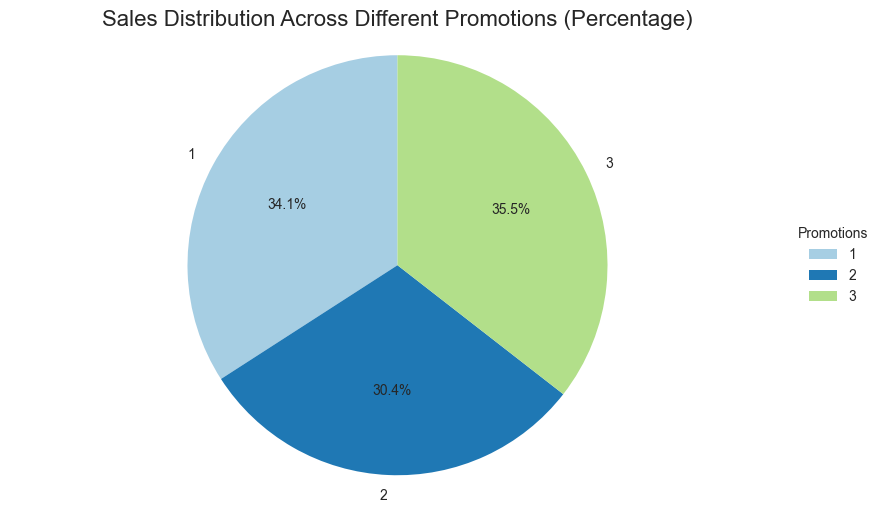

In [23]:
plt.figure(figsize=(10, 6))
wedges, texts, autotexts = plt.pie(
    sales_dist['Percentage'],
    labels=sales_dist['Promotion'],
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.Paired.colors
)

plt.legend(wedges, sales_dist['Promotion'], title="Promotions", loc="center left", bbox_to_anchor=(1, 0.5))

plt.title("Sales Distribution Across Different Promotions (Percentage)", fontsize=16)
plt.axis('equal')
plt.show()

The chart shows that promotion group 3 accounts for the highest total sales (35.5%). However, all promotion
groups contribute approximately one-third of the total sales during the promotion period.

## Weekly Sales Trend by Promotion

To understand how sales evolve over time for each promotion strategy, we plot the average weekly sales across the four-week experiment period.

This visualization helps us assess whether certain campaigns have stronger or weaker performance over time.

- Group data by `week` and `Promotion` and calculate the mean sales.
- Create a line chart to visualize the average weekly sales for each promotion group.


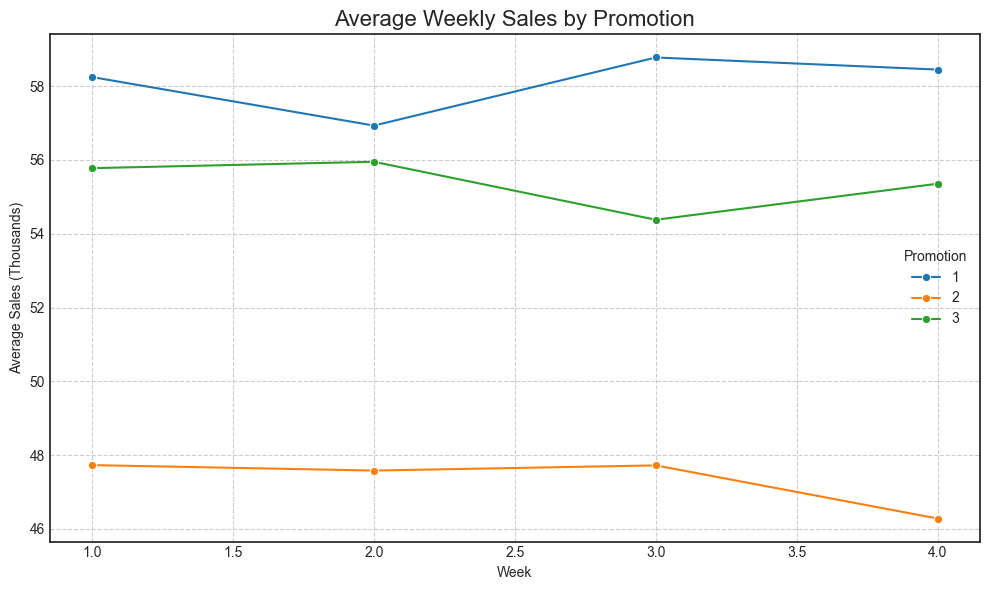

In [24]:
weekly_avg = df.groupby(['week', 'Promotion'])['SalesInThousands'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=weekly_avg, x='week', y='SalesInThousands', hue='Promotion', marker='o', palette='tab10')
plt.title("Average Weekly Sales by Promotion", fontsize=16)
plt.xlabel("Week")
plt.ylabel("Average Sales (Thousands)")
plt.grid(True, linestyle='--')
plt.tight_layout()
plt.show()

### Weekly Sales Trend Interpretation

The line chart illustrates the **average weekly sales** for each promotion group over a four-week period.

#### Observations:
- **Promotion 1** consistently performs the best, maintaining sales around **58k** with a small peak in **Week 3**.
- **Promotion 3** shows relatively stable performance, though it dips slightly in **Week 3**, recovering in Week 4.
- **Promotion 2** performs the worst throughout the period, with a noticeable **decline in Week 4**, falling to just above **46k**.

#### Conclusion:
- Promotion 1 is the most effective campaign in terms of **sustained performance** across all weeks.
- Promotion 2 underperforms and **declines over time**, indicating lower customer engagement.
- Promotion 3 stays fairly stable but does not reach the sales level of Promotion 1.

# A/B Testing

## Sample Ratio Mismatch (SRM) Check

Before running statistical comparisons between promotion groups, we need to ensure that the sample sizes are distributed evenly. An uneven distribution may indicate a randomization error or bias.

We use a **Chi-Square Goodness-of-Fit test** to determine whether the actual distribution significantly deviates from the expected equal proportions.

- Count how many samples are in each promotion group.


In [25]:
counts = df['Promotion'].value_counts().sort_index()
expected = np.array([len(df) / 3] * 3)

- Chi-square test to compare observed and expected counts.

In [26]:
chi2_stat, p_val = chisquare(counts, f_exp=expected)

print(f"Observed counts: {counts.values}")
print(f"Expected counts: {expected}")
print(f"Chi-square statistic: {chi2_stat:.2f}")
print(f"P-value: {p_val:.4f}")

Observed counts: [172 188 188]
Expected counts: [182.66666667 182.66666667 182.66666667]
Chi-square statistic: 0.93
P-value: 0.6268


- Interpretation

In [27]:
if p_val < 0.05:
    print("Sample Ratio Mismatch (SRM) detected: Group sizes are not well balanced.", end="\n")
else:
    print("No SRM detected: Group sizes are well balanced.", end="\n")

No SRM detected: Group sizes are well balanced.


### SRM Test Interpretation

The Chi-Square Goodness-of-Fit test was used to verify if the sample sizes across the three promotion groups are evenly distributed.

- **Observed counts**: [PROMO1-172, PROMO2-188, PROMO3-188]
- **Expected counts (equal distribution)**: ~183 in each group
- **Chi-square statistic**: 0.93
- **p-value**: 0.6268

Since the p-value is **greater than 0.05**, we **fail to reject the null hypothesis**, which means that the observed group sizes **do not significantly deviate** from what we would expect in a random and balanced assignment.

**Conclusion**:
No sample ratio mismatch (SRM) detected. The groups are sufficiently balanced for A/B testing to proceed.


## Analytical Confidence Intervals for Mean Sales

To estimate the uncertainty around the average weekly sales in each promotion group, we calculate **95% confidence intervals (CI)**.

This helps us understand the range within which the true mean likely falls, with 95% confidence.

- Create a function to calculate the confidence interval using the t-distribution.

In [28]:
def calc_ci(data, confidence=0.95):
    fun_mean = np.mean(data)
    standard_error = sem(data)
    n = len(data)
    h = t.ppf((1 + confidence) / 2, df=n-1) * standard_error
    return fun_mean, fun_mean - h, fun_mean + h

- Apply the function to each promotion group.
- Print the results.

In [29]:
for promo in sorted(df['Promotion'].unique()):
    sales = df[df['Promotion'] == promo]['SalesInThousands']
    mean, lower, upper = calc_ci(sales)
    print(f"Promotion {promo}: Mean = {mean:.2f}, 95% CI = [{lower:.2f}, {upper:.2f}]")

Promotion 1: Mean = 58.10, 95% CI = [55.61, 60.59]
Promotion 2: Mean = 47.33, 95% CI = [45.16, 49.50]
Promotion 3: Mean = 55.36, 95% CI = [52.95, 57.78]


### Analytical Confidence Intervals (95%) – Interpretation

We calculated the 95% confidence intervals for the mean sales in each promotion group using the t-distribution.

#### Results:
- **Promotion 1**: Mean = 58.10, 95% CI = [55.61, 60.59]
- **Promotion 2**: Mean = 47.33, 95% CI = [45.16, 49.50]
- **Promotion 3**: Mean = 55.36, 95% CI = [52.95, 57.78]

#### Interpretation:
- The confidence intervals for **Promotion 1 and 3** **overlaps**, indicating that the difference between their means is **not statistically significant**.
- Both Promotion 1 and 3 have confidence intervals that are **well above Promotion 2**, indicating **significantly better performance**.

**Conclusion**:
Promotions 1 and 3 are both effective, while Promotion 2 is clearly underperforming based on both the mean and confidence interval separation.

## Why Not Use Bootstrap CI for 3+ Groups?

Although bootstrap confidence intervals are powerful for comparing two groups, they are **not appropriate** when analyzing three or more groups. Bootstrap is well-suited for estimating the uncertainty of **a single difference** in means – for

example:
```python
mean_diff = mean(group_b) - mean(group_a)
```

But with 3 groups, there are multiple comparisons:
- Group 1 vs 2
- Group 1 vs 3
- Group 2 vs 3

Each requires a separate bootstrap, which introduces:
- **Multiple testing issues** (increased Type I error)
- No way to make a **global judgment** on whether the group variable has a significant effect overall.

### ANOVA Is Designed for This Case

ANOVA directly tests the **overall hypothesis**:
- H₀: All group means are equal
- H₁: At least one group mean is different

If significant, we then use **Tukey’s HSD** (or another post-hoc test) to see which specific groups differ.


## ANOVA Assumptions Check

Before interpreting the results of the ANOVA test, we must verify whether the key assumptions hold:

1. **Normality** within each group – checked using **Shapiro-Wilk test**
2. **Homogeneity of variances** between groups – checked using **Levene’s test**

This ensures that the use of ANOVA is statistically appropriate.


In [30]:
for group in sorted(df['Promotion'].unique()):
    sales = df[df['Promotion'] == group]['SalesInThousands']
    stat, p = shapiro(sales)
    print(f"Shapiro-Wilk Test (Promotion {group}): W={stat:.4f}, p-value={p:.4f}")
    if p < 0.05:
        print("Not normally distributed\n")
    else:
        print("Normally distributed\n")


Shapiro-Wilk Test (Promotion 1): W=0.9153, p-value=0.0000
Not normally distributed

Shapiro-Wilk Test (Promotion 2): W=0.9145, p-value=0.0000
Not normally distributed

Shapiro-Wilk Test (Promotion 3): W=0.9208, p-value=0.0000
Not normally distributed



### Assigning groups to variables for Levene's test

In [31]:
group1 = df[df['Promotion'] == 1]['SalesInThousands']
group2 = df[df['Promotion'] == 2]['SalesInThousands']
group3 = df[df['Promotion'] == 3]['SalesInThousands']

### Levene's test for homogeneity of variances

In [32]:
levene_stat, levene_p = levene(group1, group2, group3)

print(f"Levene’s Test for Equal Variances: W={levene_stat:.4f}, p-value={levene_p:.4f}")
if levene_p < 0.05:
    print("Variances are not equal – ANOVA assumptions violated.")
else:
    print("Variances are equal – safe to use ANOVA.")

Levene’s Test for Equal Variances: W=1.2697, p-value=0.2818
Variances are equal – safe to use ANOVA.


## Why ANOVA + Tukey Test Is Not Appropriate Here

Before applying ANOVA, we must verify that key assumptions are met:

1. **Normality** of data in each group (Shapiro-Wilk test)
2. **Equal variances** across groups (Levene’s test)

### Test Results:

- Levene’s Test: p > 0.05 → **Equal variances confirmed**
- Shapiro-Wilk Test: p < 0.05 for all groups → **Normality assumption violated**

### Conclusion:

Since **normality is violated** in all promotion groups, the assumptions required for parametric ANOVA are **not satisfied**.

As a result: **ANOVA + Tukey HSD test cannot be applied reliably** in this case.

Instead, we use:
- **Kruskal-Wallis test** to check for group differences in medians
- (If significant) **Dunn’s test** for post-hoc pairwise comparisons

This approach ensures the results remain statistically valid even without normal distributions.


## Kruskal-Wallis Test (Non-Parametric ANOVA)

Since the Shapiro-Wilk test showed that the sales data in all groups **is not normally distributed**, we will use the **Kruskal-Wallis test** as a non-parametric alternative to ANOVA.

The Kruskal-Wallis test evaluates whether there are statistically significant differences in the medians across the three promotion groups **without assuming normality**.


### Group the sales by promotion

In [33]:
group1 = df[df['Promotion'] == 1]['SalesInThousands']
group2 = df[df['Promotion'] == 2]['SalesInThousands']
group3 = df[df['Promotion'] == 3]['SalesInThousands']

### Perform Kruskal-Wallis test

In [34]:
h_stat, p_val = kruskal(group1, group2, group3)

### Print results

In [35]:
print(f"Kruskal-Wallis H-statistic: {h_stat:.4f}")
print(f"P-value: {p_val:.4f}")

if p_val < 0.05:
    print("Statistically significant differences exist between at least two groups.")
else:
    print("No statistically significant differences found.")

Kruskal-Wallis H-statistic: 53.2948
P-value: 0.0000
Statistically significant differences exist between at least two groups.


## Post-Hoc Analysis: Dunn's Test (Following Kruskal-Wallis)

Since the Kruskal-Wallis test revealed statistically significant differences between groups, we now perform a **Dunn’s test** with Bonferroni correction to determine **which specific pairs of promotion groups differ**.

This test is appropriate for non-parametric multiple comparisons.


In [36]:
dunn_result = sp.posthoc_dunn(df, val_col='SalesInThousands', group_col='Promotion', p_adjust='bonferroni')

print("Dunn’s Test Results (Bonferroni corrected p-values):")
print(dunn_result)

significant = (dunn_result < 0.05) & (dunn_result != 1.0)
print("\nSignificant pairwise comparisons:")
print(significant)

Dunn’s Test Results (Bonferroni corrected p-values):
              1             2             3
1  1.000000e+00  6.461842e-12  1.458660e-01
2  6.461842e-12  1.000000e+00  7.083069e-07
3  1.458660e-01  7.083069e-07  1.000000e+00

Significant pairwise comparisons:
       1      2      3
1  False   True  False
2   True  False   True
3  False   True  False


### Dunn's Post-Hoc Test Results

Since the Kruskal-Wallis test showed statistically significant differences, we used **Dunn’s test** (with Bonferroni correction) to find **which promotion groups differ**.

Promotion 1 vs 2 - 6.46e-12 - Yes
Promotion 1 vs 3 - 0.1459 - No
Promotion 2 vs 3 - 7.08e-07 - Yes

### Conclusion:

- **Promotion 2** performs **significantly worse** than both **Promotion 1** and **Promotion 3**.
- There is **no significant difference** between **Promotion 1** and **Promotion 3**.
- These results confirm the earlier insights from mean and CI analyses.


# Final Recommendation

Based on the complete statistical analysis — including descriptive statistics, confidence intervals, Kruskal-Wallis test and Dunn’s post-hoc test — we draw the following conclusions:

- **Promotion 1** has the highest average sales.
- **Promotion 2** performs **significantly worse** than both Promotion 1 and Promotion 3.
- **Promotion 1 and 3** show **no statistically significant difference** between them, suggesting they are equally effective.

### Recommendation:

We recommend adopting **Promotion 1** as the preferred marketing strategy for the fast food campaign.

If operational or logistical factors make Promotion 1 difficult to implement, **Promotion 3** serves as a **statistically comparable alternative**.

 **Avoid using Promotion 2**, due to its **consistently lower performance**, confirmed by:
- Statistically significant results in Kruskal-Wallis and Dunn's tests
- Confidence intervals and weekly performance insights
- Both analytical and visual findings

This recommendation remains valid under **non-parametric assumptions**, making it robust even when normality is violated.